# **1. Setup Library**

## **1.1 Instalasi Library**

In [1]:
%pip install pandas numpy matplotlib seaborn wordcloud nltk Sastrawi google-api-python-client python-dotenv

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.32.0 requires packaging<24,>=16.8, but you have packaging 24.1 which is incompatible.
streamlit 1.32.0 requires protobuf<5,>=3.20, but you have protobuf 7.36.2 which is incompatible.



   ---------------------------------------- 0.0/307.2 kB ? eta -:--:--
   ---------------------------------------- 0.0/307.2 kB ? eta -:--:--
   -- ------------------------------------- 20.5/307.2 kB ? eta -:--:--
   ----- --------------------------------- 41.0/307.2 kB 487.6 kB/s eta 0:00:01
   ------- ------------------------------- 61.4/307.2 kB 656.4 kB/s eta 0:00:01
   ----------- --------------------------- 92.2/307.2 kB 581.0 kB/s eta 0:00:01
   --------------- ---------------------- 122.9/307.2 kB 599.1 kB/s eta 0:00:01
   ----------------- -------------------- 143.4/307.2 kB 607.9 kB/s eta 0:00:01
   --------------------- ---------------- 174.1/307.2 kB 615.9 kB/s eta 0:00:01
   ------------------------- ------------ 204.8/307.2 kB 593.2 kB/s eta 0:00:01
   --------------------------- ---------- 225.3/307.2 kB 597.3 kB/s eta 0:00:01
   --------------------------- ---------- 225.3/307.2 kB 597.3 kB/s eta 0:00:01
   ------------------------------- ------ 256.0/307.2 kB 561.1 kB

In [3]:
%pip install youtube-comment-downloader


     ---------------------------------------- 0.0/58.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/58.5 kB ? eta -:--:--
     ------- -------------------------------- 10.2/58.5 kB ? eta -:--:--
     ------------- ------------------------ 20.5/58.5 kB 217.9 kB/s eta 0:00:01
     -------------------------- ----------- 41.0/58.5 kB 245.8 kB/s eta 0:00:01
     -------------------------------------- 58.5/58.5 kB 309.1 kB/s eta 0:00:00
     ---------------------------------------- 0.0/41.6 kB ? eta -:--:--
     ---------------------------------------- 41.6/41.6 kB 1.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/376.8 kB ? eta -:--:--
   ---- ----------------------------------- 41.0/376.8 kB 1.9 MB/s eta 0:00:01
   ---- ----------------------------------- 41.0/376.8 kB 1.9 MB/s eta 0:00:01
   ---------------- ----------------------- 153.6/376.8 kB 1.1 MB/s eta 0:00:01
   --------------------- ------------------ 204.8/376.8 kB 1.2 MB/s eta 0:00:01
 

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.32.0 requires packaging<24,>=16.8, but you have packaging 24.1 which is incompatible.
streamlit 1.32.0 requires protobuf<5,>=3.20, but you have protobuf 7.36.2 which is incompatible.


## **1.2 Import Library**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from wordcloud import WordCloud
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from googleapiclient.discovery import build
from dotenv import load_dotenv

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [4]:
import pandas as pd
from itertools import islice
from datetime import datetime
from pathlib import Path

from youtube_comment_downloader import (
    YoutubeCommentDownloader,
    SORT_BY_RECENT
)

print("Library berhasil diimpor!")

Library berhasil diimpor!


---

# **2. Pengumpulan Dataset Youtube**

## **2.1 Menentukan Sumber Data**

In [5]:
VIDEO_URL = "https://www.youtube.com/watch?v=iQo-8wx0l0Y"

TARGET_KOMENTAR = 2000

downloader = YoutubeCommentDownloader()

print("Sumber data:", VIDEO_URL)
print("Target pengambilan:", TARGET_KOMENTAR, "komentar")

Sumber data: https://www.youtube.com/watch?v=iQo-8wx0l0Y
Target pengambilan: 2000 komentar


## **2.2 Mengambil 2000 Komentar YouTube**

In [6]:
from itertools import islice

comments_generator = downloader.get_comments_from_url(
    VIDEO_URL,
    sort_by=SORT_BY_RECENT
)

comments = list(
    islice(comments_generator, TARGET_KOMENTAR)
)

print("=" * 40)
print("HASIL PENGAMBILAN KOMENTAR")
print("=" * 40)
print(f"Target komentar       : {TARGET_KOMENTAR}")
print(f"Komentar berhasil     : {len(comments)}")
print(f"Status                : {'Berhasil' if len(comments) > 0 else 'Tidak ada data'}")

HASIL PENGAMBILAN KOMENTAR
Target komentar       : 2000
Komentar berhasil     : 2000
Status                : Berhasil


## **2.3 Membuat Dataframe**

In [7]:
df_raw = pd.DataFrame(comments)

print("=" * 40)
print("INFORMASI DATASET")
print("=" * 40)

print(f"Jumlah baris : {df_raw.shape[0]}")
print(f"Jumlah kolom : {df_raw.shape[1]}")

print("\nNama kolom:")
print(df_raw.columns.tolist())

display(df_raw.head(10))

INFORMASI DATASET
Jumlah baris : 2000
Jumlah kolom : 11

Nama kolom:
['cid', 'text', 'time', 'author', 'channel', 'votes', 'replies', 'photo', 'heart', 'reply', 'time_parsed']


,cid,text,time,author,channel,votes,replies,photo,heart,reply,time_parsed
0,UgxhHCBQvTs3ABmVO-h4AaABAg,Nak? Kalau kamu nanti disana pilih kita (ayah ...,1 jam yang lalu,@rio....202,UC3AiqJC7FFDeaHlHklRW55w,0,,https://yt3.ggpht.com/Gam4iepdjkr8LXp4M5b-hG6e...,False,False,1.795623e+09
1,Ugx8lYmeiG08FI1tWBh4AaABAg,"Untuk abang, kakak, ayah dan mamak\nMakasih un...",3 jam yang lalu,@DeboraIrawati-v7o,UCc4p4s3Xq3wFjFtbmuriB6Q,0,,https://yt3.ggpht.com/Oc36L4aQoxZRwyiL6Jjr4hBX...,False,False,1.795616e+09
2,Ugwg_zWd5PLxbpcRksp4AaABAg,Saat engkau tertidur\nAku pergi menghibur\nBed...,5 jam yang lalu,@martabak_telor_bebek,UC9ydlUVur0BpvReey79QXdA,0,,https://yt3.ggpht.com/ytc/AIdro_nr7Ep0aROB9ZQM...,False,False,1.795608e+09
3,Ugz8gbZjalQVllBOT-N4AaABAg,"Untuk adek adekku, teteh bersyukur ada kalian,...",5 jam yang lalu (diedit),@sitikamila2368,UCpKRtU6MqssQ7Cwmtt709iw,0,,https://yt3.ggpht.com/ytc/AIdro_kSGfJDEc-ehaGC...,False,False,1.795608e+09
4,UgwHVqTzW1yBUWzKcq94AaABAg,Tante aku pulang lebih awal dari pada semua ke...,7 jam yang lalu,@YuliusSulistiadi-n7c,UCOb_Dy99-DsS9H3V4-6aEWQ,0,,https://yt3.ggpht.com/ytc/AIdro_mS_CCK-QXw5Ab0...,False,False,1.795601e+09
5,Ugz-WiXMOb48SoIhtkh4AaABAg,Aku kangen tante aki😢😢,7 jam yang lalu,@YuliusSulistiadi-n7c,UCOb_Dy99-DsS9H3V4-6aEWQ,0,,https://yt3.ggpht.com/ytc/AIdro_mS_CCK-QXw5Ab0...,False,False,1.795601e+09
6,Ugyf9PQaGe3F_B2olM54AaABAg,"Sehat"" untuk semuanya, kita tau semua harus ki...",8 jam yang lalu,@jeep6452,UCv3HC-vKXfBx9QuRs-QR4ow,0,,https://yt3.ggpht.com/ytc/AIdro_moxLIs0SC8makW...,False,False,1.795598e+09
7,UgzNplEpRGfysiakGJ14AaABAg,"Dear Muhammad Ibrahim Khalili ( Alil ), 6 tahu...",11 jam yang lalu,@Mikhali-r2g,UCA9iyOn0A6YkED-HyskR3Gg,2,,https://yt3.ggpht.com/M7myNnvEa97c6zxVCfGrkeF8...,False,False,1.795587e+09
8,Ugy16KPQLea6u46mopZ4AaABAg,Mati klian,11 jam yang lalu,@alvlinja,UCjig8qHK1EASwzg2OBLxLFw,0,,https://yt3.ggpht.com/ytc/AIdro_lVwICIdXFa1ZqP...,False,False,1.795587e+09
9,Ugw5DYMjFVtym_hcBUN4AaABAg,"jd inget lagu ""satu rasa"" by sahara",12 jam yang lalu,@mcbbirowo,UCnMMf-OzaSri_xFlHTxHYjg,0,,https://yt3.ggpht.com/KIjS0mnBCtPtvMc5J2Znsc90...,False,False,1.795583e+09


## **2.4 Menyimpan Dataset Mentah**

In [10]:
from pathlib import Path

Path("data/raw").mkdir(parents=True, exist_ok=True)

df_raw.to_csv(
    "../data/raw/komentar_nina.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset berhasil disimpan!")
print(f"Lokasi: ../data/raw/komentar_nina.csv")
print(f"Total data: {len(df_raw)} komentar")

Dataset berhasil disimpan!
Lokasi: ../data/raw/komentar_nina.csv
Total data: 2000 komentar


---

# **3. Exploratory Data Analysis**

## **3.1 Memuat Dataset Mentah**

In [12]:
from pathlib import Path
import pandas as pd

# Memuat dataset mentah
DATA_PATH = Path("../data/raw/komentar_nina.csv")

df_raw = pd.read_csv(DATA_PATH)

print("=" * 45)
print("DATASET BERHASIL DIMUAT")
print("=" * 45)
print(f"Jumlah komentar : {len(df_raw)}")
print(f"Jumlah kolom    : {len(df_raw.columns)}")
print(f"Ukuran dataset  : {df_raw.shape}")

display(df_raw.head(5))

DATASET BERHASIL DIMUAT
Jumlah komentar : 2000
Jumlah kolom    : 11
Ukuran dataset  : (2000, 11)


,cid,text,time,author,channel,votes,replies,photo,heart,reply,time_parsed
0,UgxhHCBQvTs3ABmVO-h4AaABAg,Nak? Kalau kamu nanti disana pilih kita (ayah ...,1 jam yang lalu,@rio....202,UC3AiqJC7FFDeaHlHklRW55w,0,NaN,https://yt3.ggpht.com/Gam4iepdjkr8LXp4M5b-hG6e...,False,False,1.795623e+09
1,Ugx8lYmeiG08FI1tWBh4AaABAg,"Untuk abang, kakak, ayah dan mamak\nMakasih un...",3 jam yang lalu,@DeboraIrawati-v7o,UCc4p4s3Xq3wFjFtbmuriB6Q,0,NaN,https://yt3.ggpht.com/Oc36L4aQoxZRwyiL6Jjr4hBX...,False,False,1.795616e+09
2,Ugwg_zWd5PLxbpcRksp4AaABAg,Saat engkau tertidur\nAku pergi menghibur\nBed...,5 jam yang lalu,@martabak_telor_bebek,UC9ydlUVur0BpvReey79QXdA,0,NaN,https://yt3.ggpht.com/ytc/AIdro_nr7Ep0aROB9ZQM...,False,False,1.795608e+09
3,Ugz8gbZjalQVllBOT-N4AaABAg,"Untuk adek adekku, teteh bersyukur ada kalian,...",5 jam yang lalu (diedit),@sitikamila2368,UCpKRtU6MqssQ7Cwmtt709iw,0,NaN,https://yt3.ggpht.com/ytc/AIdro_kSGfJDEc-ehaGC...,False,False,1.795608e+09
4,UgwHVqTzW1yBUWzKcq94AaABAg,Tante aku pulang lebih awal dari pada semua ke...,7 jam yang lalu,@YuliusSulistiadi-n7c,UCOb_Dy99-DsS9H3V4-6aEWQ,0,NaN,https://yt3.ggpht.com/ytc/AIdro_mS_CCK-QXw5Ab0...,False,False,1.795601e+09


## **3.2 Memeriksa Informasi Dataset**

In [13]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   cid          2000 non-null   object 
 1   text         2000 non-null   object 
 2   time         2000 non-null   object 
 3   author       2000 non-null   object 
 4   channel      2000 non-null   object 
 5   votes        2000 non-null   int64  
 6   replies      151 non-null    float64
 7   photo        2000 non-null   object 
 8   heart        2000 non-null   bool   
 9   reply        2000 non-null   bool   
 10  time_parsed  2000 non-null   float64
dtypes: bool(2), float64(2), int64(1), object(6)
memory usage: 144.7+ KB


## **3.3 Memeriksa Missing Value**

In [14]:
missing_data = pd.DataFrame({
    "Jumlah Missing": df_raw.isnull().sum(),
    "Persentase Missing (%)": (
        df_raw.isnull().mean() * 100
    ).round(2)
})

display(missing_data)

,Jumlah Missing,Persentase Missing (%)
cid,0,0.00
text,0,0.00
time,0,0.00
author,0,0.00
channel,0,0.00
votes,0,0.00
replies,1849,92.45
photo,0,0.00
heart,0,0.00
reply,0,0.00


## **3.4 Memeriksa Duplikasi Komentar**

In [15]:
# Menghitung jumlah komentar duplikat
jumlah_duplikat = df_raw["text"].duplicated().sum()

persentase_duplikat = (
    jumlah_duplikat / len(df_raw) * 100
)

print("=" * 45)
print("PEMERIKSAAN DUPLIKASI KOMENTAR")
print("=" * 45)
print(f"Total komentar       : {len(df_raw)}")
print(f"Komentar duplikat    : {jumlah_duplikat}")
print(f"Persentase duplikat  : {persentase_duplikat:.2f}%")
print(f"Komentar unik        : {len(df_raw) - jumlah_duplikat}")

PEMERIKSAAN DUPLIKASI KOMENTAR
Total komentar       : 2000
Komentar duplikat    : 90
Persentase duplikat  : 4.50%
Komentar unik        : 1910


In [16]:
# Menampilkan contoh komentar duplikat
data_duplikat = df_raw[
    df_raw["text"].duplicated(keep=False)
].sort_values("text")

display(data_duplikat[["text", "author"]].head(10))

,text,author
824,.,@suothachannel
723,.,@BootFanny
715,.,@wahyuhidayat7673
625,.,@armandfajar9305
1030,.,@GamerBlack-f4k
1032,.,@armandfajar9305
1074,.,@bluze_hub
1223,.,@Nayla-l2i
1243,.,@usugin12
1430,.,@DavideSanton-w4x


## **3.5 Analisis Panjang Komentar**

In [17]:
# Menghitung panjang setiap komentar berdasarkan jumlah karakter
df_raw["panjang_karakter"] = df_raw["text"].astype(str).str.len()

# Menghitung statistik panjang komentar
statistik_panjang = df_raw["panjang_karakter"].describe()

print("=" * 45)
print("STATISTIK PANJANG KOMENTAR")
print("=" * 45)

display(statistik_panjang)

STATISTIK PANJANG KOMENTAR


count    2000.000000
mean      176.332500
std       295.242699
min         1.000000
25%        25.000000
50%        78.000000
75%       213.000000
max      5115.000000
Name: panjang_karakter, dtype: float64

## **3.6 Visualisasi Distribusi Panjang Komentar**

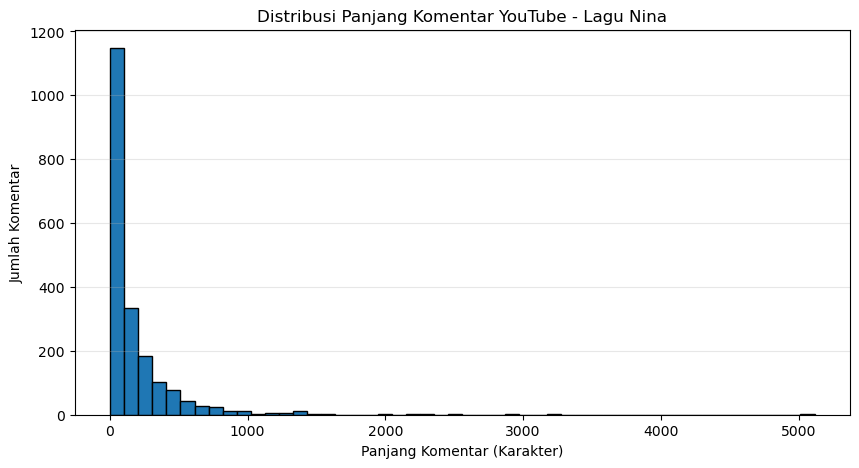

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_raw["panjang_karakter"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribusi Panjang Komentar YouTube - Lagu Nina")
plt.xlabel("Panjang Komentar (Karakter)")
plt.ylabel("Jumlah Komentar")
plt.grid(axis="y", alpha=0.3)

plt.show()

## **3.3 Analisis Jumlah Kata per Komentar**

In [19]:
# Menghitung jumlah kata pada setiap komentar
df_raw["jumlah_kata"] = (
    df_raw["text"]
    .astype(str)
    .str.split()
    .str.len()
)

print("=" * 45)
print("STATISTIK JUMLAH KATA PER KOMENTAR")
print("=" * 45)

display(df_raw["jumlah_kata"].describe())

STATISTIK JUMLAH KATA PER KOMENTAR


count    2000.000000
mean       28.769500
std        47.787061
min         1.000000
25%         4.000000
50%        13.000000
75%        34.000000
max       836.000000
Name: jumlah_kata, dtype: float64

## **3.8 Memeriksa Komentar Terpendek dan Terpanjang**

In [20]:
# Mengurutkan komentar berdasarkan jumlah kata
df_terurut = df_raw.sort_values(
    by="jumlah_kata",
    ascending=True
)

print("=" * 45)
print("5 KOMENTAR TERPENDEK")
print("=" * 45)

display(
    df_terurut[["text", "jumlah_kata"]].head(5)
)

print("\n" + "=" * 45)
print("5 KOMENTAR TERPANJANG")
print("=" * 45)

display(
    df_terurut[["text", "jumlah_kata"]].tail(5)
)

5 KOMENTAR TERPENDEK


,text,jumlah_kata
1999,03:33,1
1117,0:2,1
343,2:34,1
340,ALSYA5♥♪🥺🫰🏻💬🫸🏻🫷🏻💝💗💕💖🥺🥹,1
1154,❤,1



5 KOMENTAR TERPANJANG


,text,jumlah_kata
1404,hay aku farel aku sekarang berumur 16 tahun ak...,426
1670,hai nama aku stendly umur 16 tahun cita cita k...,446
437,sebagai anak pertama yang punya adik di luar s...,449
545,"Sejak lagu .Feast yg berjudul ""Nina"" rilis, sa...",507
1,"Untuk abang, kakak, ayah dan mamak\nMakasih un...",836


## **3.9 Mengamati Sampel Komentar Secara Acak**

In [21]:
# Mengambil 10 komentar secara acak
sampel_komentar = df_raw.sample(
    n=10,
    random_state=42
)

print("=" * 45)
print("10 SAMPEL KOMENTAR SECARA ACAK")
print("=" * 45)

display(
    sampel_komentar[["text", "jumlah_kata"]]
)

10 SAMPEL KOMENTAR SECARA ACAK


,text,jumlah_kata
1860,"Saat baca komentarnya, aku sadar ternyata aku ...",10
353,halo aku firaz umur ku baru 9 tahun dan untuk ...,77
1333,Jadi lebih baik dibanding diriku... Hit me so ...,10
905,Untuk diriku sendiri: apapun yang terjadi beso...,36
1289,lagu ini tuub enak banervss,5
1273,"Hai rena, aku juga rena. Aku sudah melewati ma...",48
938,"SEAN, KAIRO dan Istriku Intan ❤",6
1731,Rf. F f,3
65,Dejavu,1
1323,hell nawh,2


---

# **4. Preprocessing**

## **4.1 Membuat Salinan Dataset**

### **Preprocessing Data**

Tahap preprocessing dilakukan untuk membersihkan dan mempersiapkan data komentar YouTube agar dapat digunakan dalam analisis frekuensi kata.

Tahapan preprocessing meliputi:
1. Cleaning
2. Case Folding
3. Normalisasi
4. Tokenisasi
5. Stopword Removal
6. Stemming

In [22]:
# Membuat salinan dataset untuk preprocessing
df_process = df_raw.copy()

print("=" * 45)
print("PERSIAPAN DATA PREPROCESSING")
print("=" * 45)

print(f"Jumlah data asli       : {len(df_raw)}")
print(f"Jumlah data proses     : {len(df_process)}")
print(f"Jumlah kolom           : {len(df_process.columns)}")

display(df_process[["text"]].head(5))

PERSIAPAN DATA PREPROCESSING
Jumlah data asli       : 2000
Jumlah data proses     : 2000
Jumlah kolom           : 13


,text
0,Nak? Kalau kamu nanti disana pilih kita (ayah ...
1,"Untuk abang, kakak, ayah dan mamak\nMakasih un..."
2,Saat engkau tertidur\nAku pergi menghibur\nBed...
3,"Untuk adek adekku, teteh bersyukur ada kalian,..."
4,Tante aku pulang lebih awal dari pada semua ke...


## **4.2 Cleaning**

### **4.2.1 Membuat Fungsi Cleaning**

In [23]:
import re
import unicodedata

def cleaning_text(text):
    # Mengubah nilai menjadi string
    text = str(text)

    # Menghapus URL
    text = re.sub(r"http\S+|www\.\S+", "", text)

    # Menghapus mention pengguna
    text = re.sub(r"@\w+", "", text)

    # Menghapus simbol hashtag, tetapi mempertahankan katanya
    text = re.sub(r"#", "", text)

    # Menghapus emoji dan karakter simbol
    text = "".join(
        char for char in text
        if unicodedata.category(char)[0] != "S"
    )

    # Menghapus karakter yang bukan huruf, angka, atau spasi
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Merapikan spasi berlebih
    text = re.sub(r"\s+", " ", text).strip()

    return text

### **4.2.2 Menerapkan Cleaning**

In [24]:
# Menerapkan fungsi cleaning pada seluruh komentar
df_process["cleaned_text"] = df_process["text"].apply(cleaning_text)

print("=" * 45)
print("HASIL PENERAPAN CLEANING")
print("=" * 45)

print(f"Total komentar       : {len(df_process)}")
print(f"Komentar kosong     : {(df_process['cleaned_text'] == '').sum()}")
print(f"Komentar tidak kosong: {(df_process['cleaned_text'] != '').sum()}")

display(
    df_process[["text", "cleaned_text"]].head(10)
)

HASIL PENERAPAN CLEANING
Total komentar       : 2000
Komentar kosong     : 84
Komentar tidak kosong: 1916


,text,cleaned_text
0,Nak? Kalau kamu nanti disana pilih kita (ayah ...,Nak Kalau kamu nanti disana pilih kita ayah bu...
1,"Untuk abang, kakak, ayah dan mamak\nMakasih un...",Untuk abang kakak ayah dan mamak Makasih untuk...
2,Saat engkau tertidur\nAku pergi menghibur\nBed...,Saat engkau tertidur Aku pergi menghibur Beda ...
3,"Untuk adek adekku, teteh bersyukur ada kalian,...",Untuk adek adekku teteh bersyukur ada kalian t...
4,Tante aku pulang lebih awal dari pada semua ke...,Tante aku pulang lebih awal dari pada semua ke...
5,Aku kangen tante aki😢😢,Aku kangen tante aki
6,"Sehat"" untuk semuanya, kita tau semua harus ki...",Sehat untuk semuanya kita tau semua harus kita...
7,"Dear Muhammad Ibrahim Khalili ( Alil ), 6 tahu...",Dear Muhammad Ibrahim Khalili Alil 6 tahun aya...
8,Mati klian,Mati klian
9,"jd inget lagu ""satu rasa"" by sahara",jd inget lagu satu rasa by sahara


### **4.2.3 Memeriksa Komentar yang Menjadi Kosong**

In [25]:
# Mengambil komentar yang menjadi kosong setelah cleaning
komentar_kosong = df_process[
    df_process["cleaned_text"] == ""
]

print("=" * 45)
print("PEMERIKSAAN KOMENTAR KOSONG")
print("=" * 45)

print(f"Jumlah komentar kosong: {len(komentar_kosong)}")

display(
    komentar_kosong[["text"]].head(20)
)

PEMERIKSAAN KOMENTAR KOSONG
Jumlah komentar kosong: 84


,text
42,😂
63,👍👍👍👍👍
66,👍👍👍👍👍
80,😢
98,😍
119,😭
218,😢
239,💔
268,👍🏼
273,.


### **4.2.4 Menghapus Komentar Kosong**

In [26]:
# Menghapus komentar yang kosong setelah cleaning
jumlah_sebelum = len(df_process)

df_process = df_process[
    df_process["cleaned_text"] != ""
].copy()

jumlah_sesudah = len(df_process)
jumlah_dihapus = jumlah_sebelum - jumlah_sesudah

print("=" * 45)
print("PENGHAPUSAN KOMENTAR KOSONG")
print("=" * 45)

print(f"Jumlah sebelum       : {jumlah_sebelum}")
print(f"Jumlah dihapus       : {jumlah_dihapus}")
print(f"Jumlah setelah       : {jumlah_sesudah}")

PENGHAPUSAN KOMENTAR KOSONG
Jumlah sebelum       : 2000
Jumlah dihapus       : 84
Jumlah setelah       : 1916


### **4.2.5 Pemeriksaan Duplikasi Setelah Cleaning**

In [27]:
# Menghitung duplikasi berdasarkan teks hasil cleaning
jumlah_duplikat_clean = df_process["cleaned_text"].duplicated().sum()

print("=" * 45)
print("DUPLIKASI SETELAH CLEANING")
print("=" * 45)

print(f"Total komentar       : {len(df_process)}")
print(f"Komentar duplikat    : {jumlah_duplikat_clean}")
print(f"Komentar unik        : {len(df_process) - jumlah_duplikat_clean}")

# Menampilkan contoh komentar duplikat
data_duplikat_clean = df_process[
    df_process["cleaned_text"].duplicated(keep=False)
].sort_values("cleaned_text")

display(
    data_duplikat_clean[
        ["text", "cleaned_text"]
    ].head(10)
)

DUPLIKASI SETELAH CLEANING
Total komentar       : 1916
Komentar duplikat    : 70
Komentar unik        : 1846


,text,cleaned_text
1969,2.34,2 34
1968,2:34,2 34
343,2:34,2 34
350,3:34,3 34
627,3:34,3 34
1242,3:35,3 35
1105,3:35,3 35
863,3:35,3 35
986,3:35,3 35
359,Aamiin,Aamiin


### **4.2.6 Memperbarui Fungsi Cleaning**

In [28]:
def cleaning_text(text):
    text = str(text)

    # Menghapus URL
    text = re.sub(r"http\S+|www\.\S+", "", text)

    # Menghapus mention
    text = re.sub(r"@\w+", "", text)

    # Menghapus komentar yang hanya berisi timestamp
    if re.fullmatch(r"\s*\d{1,2}[:.]\d{2}(?:[:.]\d{2})?\s*", text):
        return ""

    # Menghapus simbol hashtag, mempertahankan katanya
    text = re.sub(r"#", "", text)

    # Menghapus emoji dan simbol
    text = "".join(
        char for char in text
        if unicodedata.category(char)[0] != "S"
    )

    # Menghapus tanda baca
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Merapikan spasi
    text = re.sub(r"\s+", " ", text).strip()

    return text

### **4.2.7 Mengulang Cleaning dari Data Asli**

In [29]:
# Mengembalikan dataset kerja dari data asli
df_process = df_raw.copy()

# Menerapkan fungsi cleaning terbaru
df_process["cleaned_text"] = df_process["text"].apply(cleaning_text)

# Menghapus komentar kosong
df_process = df_process[
    df_process["cleaned_text"] != ""
].copy()

print("=" * 45)
print("HASIL CLEANING SETELAH PERBAIKAN")
print("=" * 45)

print(f"Data awal             : {len(df_raw)}")
print(f"Komentar dihapus      : {len(df_raw) - len(df_process)}")
print(f"Data setelah cleaning : {len(df_process)}")

display(df_process[["text", "cleaned_text"]].head(10))

HASIL CLEANING SETELAH PERBAIKAN
Data awal             : 2000
Komentar dihapus      : 110
Data setelah cleaning : 1890


,text,cleaned_text
0,Nak? Kalau kamu nanti disana pilih kita (ayah ...,Nak Kalau kamu nanti disana pilih kita ayah bu...
1,"Untuk abang, kakak, ayah dan mamak\nMakasih un...",Untuk abang kakak ayah dan mamak Makasih untuk...
2,Saat engkau tertidur\nAku pergi menghibur\nBed...,Saat engkau tertidur Aku pergi menghibur Beda ...
3,"Untuk adek adekku, teteh bersyukur ada kalian,...",Untuk adek adekku teteh bersyukur ada kalian t...
4,Tante aku pulang lebih awal dari pada semua ke...,Tante aku pulang lebih awal dari pada semua ke...
5,Aku kangen tante aki😢😢,Aku kangen tante aki
6,"Sehat"" untuk semuanya, kita tau semua harus ki...",Sehat untuk semuanya kita tau semua harus kita...
7,"Dear Muhammad Ibrahim Khalili ( Alil ), 6 tahu...",Dear Muhammad Ibrahim Khalili Alil 6 tahun aya...
8,Mati klian,Mati klian
9,"jd inget lagu ""satu rasa"" by sahara",jd inget lagu satu rasa by sahara


### **4.2.8 Ringkasan Duplikasi**

In [30]:
jumlah_duplikat_clean = df_process["cleaned_text"].duplicated().sum()

print("=" * 45)
print("PEMERIKSAAN DUPLIKASI TERBARU")
print("=" * 45)

print(f"Total komentar       : {len(df_process)}")
print(f"Komentar duplikat    : {jumlah_duplikat_clean}")
print(f"Komentar unik        : {len(df_process) - jumlah_duplikat_clean}")

PEMERIKSAAN DUPLIKASI TERBARU
Total komentar       : 1890
Komentar duplikat    : 64
Komentar unik        : 1826


### **4.2.9 Menghapus Komentar Duplikat**

In [31]:
jumlah_sebelum = len(df_process)

df_process = df_process.drop_duplicates(
    subset="cleaned_text",
    keep="first"
).copy()

jumlah_sesudah = len(df_process)
jumlah_dihapus = jumlah_sebelum - jumlah_sesudah

print("=" * 45)
print("PENGHAPUSAN KOMENTAR DUPLIKAT")
print("=" * 45)

print(f"Jumlah sebelum       : {jumlah_sebelum}")
print(f"Jumlah duplikat      : {jumlah_dihapus}")
print(f"Jumlah setelah       : {jumlah_sesudah}")

PENGHAPUSAN KOMENTAR DUPLIKAT
Jumlah sebelum       : 1890
Jumlah duplikat      : 64
Jumlah setelah       : 1826


## **4.3 Case Folding**

In [32]:
# Menerapkan case folding
df_process["case_folding"] = (
    df_process["cleaned_text"].str.lower()
)

print("=" * 45)
print("HASIL CASE FOLDING")
print("=" * 45)

print(f"Total komentar : {len(df_process)}")

display(
    df_process[
        ["cleaned_text", "case_folding"]
    ].head(10)
)

HASIL CASE FOLDING
Total komentar : 1826


,cleaned_text,case_folding
0,Nak Kalau kamu nanti disana pilih kita ayah bu...,nak kalau kamu nanti disana pilih kita ayah bu...
1,Untuk abang kakak ayah dan mamak Makasih untuk...,untuk abang kakak ayah dan mamak makasih untuk...
2,Saat engkau tertidur Aku pergi menghibur Beda ...,saat engkau tertidur aku pergi menghibur beda ...
3,Untuk adek adekku teteh bersyukur ada kalian t...,untuk adek adekku teteh bersyukur ada kalian t...
4,Tante aku pulang lebih awal dari pada semua ke...,tante aku pulang lebih awal dari pada semua ke...
5,Aku kangen tante aki,aku kangen tante aki
6,Sehat untuk semuanya kita tau semua harus kita...,sehat untuk semuanya kita tau semua harus kita...
7,Dear Muhammad Ibrahim Khalili Alil 6 tahun aya...,dear muhammad ibrahim khalili alil 6 tahun aya...
8,Mati klian,mati klian
9,jd inget lagu satu rasa by sahara,jd inget lagu satu rasa by sahara


## **4.4 Normalisasi Kata Baku**

In [33]:
# Kamus normalisasi kata tidak baku
normalisasi_kata = {
    "yg": "yang",
    "gak": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "jd": "jadi",
    "dgn": "dengan",
    "krn": "karena",
    "bgt": "banget",
    "utk": "untuk",
    "adek": "adik",
}

def normalisasi_text(text):
    kata = text.split()

    hasil = [
        normalisasi_kata.get(token, token)
        for token in kata
    ]

    return " ".join(hasil)


df_process["normalisasi"] = (
    df_process["case_folding"].apply(normalisasi_text)
)

print("=" * 45)
print("HASIL NORMALISASI")
print("=" * 45)

display(
    df_process[
        ["case_folding", "normalisasi"]
    ].head(15)
)

HASIL NORMALISASI


,case_folding,normalisasi
0,nak kalau kamu nanti disana pilih kita ayah bu...,nak kalau kamu nanti disana pilih kita ayah bu...
1,untuk abang kakak ayah dan mamak makasih untuk...,untuk abang kakak ayah dan mamak makasih untuk...
2,saat engkau tertidur aku pergi menghibur beda ...,saat engkau tertidur aku pergi menghibur beda ...
3,untuk adek adekku teteh bersyukur ada kalian t...,untuk adik adekku teteh bersyukur ada kalian t...
4,tante aku pulang lebih awal dari pada semua ke...,tante aku pulang lebih awal dari pada semua ke...
5,aku kangen tante aki,aku kangen tante aki
6,sehat untuk semuanya kita tau semua harus kita...,sehat untuk semuanya kita tau semua harus kita...
7,dear muhammad ibrahim khalili alil 6 tahun aya...,dear muhammad ibrahim khalili alil 6 tahun aya...
8,mati klian,mati klian
9,jd inget lagu satu rasa by sahara,jadi inget lagu satu rasa by sahara


### **4.4.1 Mengidentfikasi Kata yang Sering Muncul**

In [34]:
from collections import Counter

# Menggabungkan seluruh kata dari hasil case folding
semua_kata = " ".join(
    df_process["case_folding"]
).split()

# Menghitung frekuensi setiap kata
frekuensi_kata = Counter(semua_kata)

# Menampilkan 50 kata yang paling sering muncul
kata_teratas = pd.DataFrame(
    frekuensi_kata.most_common(50),
    columns=["Kata", "Frekuensi"]
)

display(kata_teratas)

,Kata,Frekuensi
0,aku,2058
1,dan,1268
2,yang,960
3,ini,774
4,untuk,746
5,di,674
6,ku,547
7,bisa,535
8,kalian,527
9,yg,439


### **4.4.2 Melengkapi Kamus Normalisasi**

In [35]:
# Kamus normalisasi kata tidak baku
normalisasi_kata.update({
    "udh": "sudah",
    "udah": "sudah",
    "blm": "belum",
    "belom": "belum",
    "blom": "belum",
    "bkn": "bukan",
    "krn": "karena",
    "karna": "karena",
    "sm": "sama",
    "sma": "sama",
    "dpt": "dapat",
    "dr": "dari",
    "d": "di",
    "tdk": "tidak",
    "tak": "tidak",
    "gk": "tidak",
    "emg": "memang",
    "emang": "memang",
    "bbrp": "beberapa",
    "tp": "tapi",
    "aja": "saja",
    "klo": "kalau",
    "kalo": "kalau",
    "km": "kamu",
    "sy": "saya",
    "aq": "aku",
    "gw": "saya",
    "gue": "saya",
})

### **4.4.3 Menerapkan Ulang Normalisasi**

In [36]:
df_process["normalisasi"] = (
    df_process["case_folding"].apply(normalisasi_text)
)

display(
    df_process[
        ["case_folding", "normalisasi"]
    ].head(15)
)

,case_folding,normalisasi
0,nak kalau kamu nanti disana pilih kita ayah bu...,nak kalau kamu nanti disana pilih kita ayah bu...
1,untuk abang kakak ayah dan mamak makasih untuk...,untuk abang kakak ayah dan mamak makasih untuk...
2,saat engkau tertidur aku pergi menghibur beda ...,saat engkau tertidur aku pergi menghibur beda ...
3,untuk adek adekku teteh bersyukur ada kalian t...,untuk adik adekku teteh bersyukur ada kalian t...
4,tante aku pulang lebih awal dari pada semua ke...,tante aku pulang lebih awal dari pada semua ke...
5,aku kangen tante aki,aku kangen tante aki
6,sehat untuk semuanya kita tau semua harus kita...,sehat untuk semuanya kita tau semua harus kita...
7,dear muhammad ibrahim khalili alil 6 tahun aya...,dear muhammad ibrahim khalili alil 6 tahun aya...
8,mati klian,mati klian
9,jd inget lagu satu rasa by sahara,jadi inget lagu satu rasa by sahara


### **4.4.4 Menambahkan Variasi Kata**

In [37]:
normalisasi_kata.update({
    "adekku": "adikku",
    "adekmu": "adikmu",
    "adeknya": "adiknya",
    "adek2": "adik adik",
})

In [38]:
# Menghapus aturan yang terlalu ambigu
normalisasi_kata.pop("d", None)

'di'

In [39]:
df_process["normalisasi"] = (
    df_process["case_folding"].apply(normalisasi_text)
)

### **4.4.5 Memeriksa Hasil Normalisasi**

In [40]:
from collections import Counter

kata_normalisasi = Counter(
    " ".join(df_process["normalisasi"]).split()
)

kata_pemeriksaan = [
    "yg", "yang",
    "udh", "sudah",
    "adek", "adik",
    "adekku", "adikku"
]

hasil_pemeriksaan = pd.DataFrame({
    "Kata": kata_pemeriksaan,
    "Frekuensi": [
        kata_normalisasi[kata]
        for kata in kata_pemeriksaan
    ]
})

display(hasil_pemeriksaan)

,Kata,Frekuensi
0,yg,0
1,yang,1399
2,udh,0
3,sudah,483
4,adek,0
5,adik,212
6,adekku,0
7,adikku,72


## **4.5 Tokenisasi**

In [41]:
# Melakukan tokenisasi
df_process["tokens"] = (
    df_process["normalisasi"].apply(lambda text: text.split())
)

print("=" * 45)
print("HASIL TOKENISASI")
print("=" * 45)

print(f"Total komentar : {len(df_process)}")

display(
    df_process[
        ["normalisasi", "tokens"]
    ].head(10)
)

HASIL TOKENISASI
Total komentar : 1826


,normalisasi,tokens
0,nak kalau kamu nanti disana pilih kita ayah bu...,"[nak, kalau, kamu, nanti, disana, pilih, kita,..."
1,untuk abang kakak ayah dan mamak makasih untuk...,"[untuk, abang, kakak, ayah, dan, mamak, makasi..."
2,saat engkau tertidur aku pergi menghibur beda ...,"[saat, engkau, tertidur, aku, pergi, menghibur..."
3,untuk adik adikku teteh bersyukur ada kalian t...,"[untuk, adik, adikku, teteh, bersyukur, ada, k..."
4,tante aku pulang lebih awal dari pada semua ke...,"[tante, aku, pulang, lebih, awal, dari, pada, ..."
5,aku kangen tante aki,"[aku, kangen, tante, aki]"
6,sehat untuk semuanya kita tau semua harus kita...,"[sehat, untuk, semuanya, kita, tau, semua, har..."
7,dear muhammad ibrahim khalili alil 6 tahun aya...,"[dear, muhammad, ibrahim, khalili, alil, 6, ta..."
8,mati klian,"[mati, klian]"
9,jadi inget lagu satu rasa by sahara,"[jadi, inget, lagu, satu, rasa, by, sahara]"


## **4.6 Stopword Removal**

In [42]:
import nltk
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import (
    StopWordRemoverFactory
)

# Mengunduh daftar stopword NLTK
nltk.download("stopwords")

# Menggabungkan stopword NLTK dan Sastrawi
stopwords_indonesia = set(stopwords.words("indonesian"))

factory = StopWordRemoverFactory()
stopwords_sastrawi = set(factory.get_stop_words())

stopwords_indonesia.update(stopwords_sastrawi)

# Menambahkan stopword umum
stopwords_tambahan = {
    "aja", "saja", "nih", "sih", "dong",
    "deh", "kok", "lah", "pun", "ya"
}

stopwords_indonesia.update(stopwords_tambahan)

print("Jumlah stopword:", len(stopwords_indonesia))
print("\nContoh stopword:")
print(sorted(list(stopwords_indonesia))[:30])

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Asus\AppData\Roaming\nltk_data...


Jumlah stopword: 778

Contoh stopword:
['ada', 'adalah', 'adanya', 'adapun', 'agak', 'agaknya', 'agar', 'aja', 'akan', 'akankah', 'akhir', 'akhiri', 'akhirnya', 'aku', 'akulah', 'amat', 'amatlah', 'anda', 'andalah', 'antar', 'antara', 'antaranya', 'anu', 'apa', 'apaan', 'apabila', 'apakah', 'apalagi', 'apatah', 'artinya']


[nltk_data]   Unzipping corpora\stopwords.zip.


### **4.6.1 Menentukan Kata yang dipertahankan**

In [43]:
# Kata yang harus dipertahankan dalam analisis
protected_words = {
    "aku", "saya", "kamu", "anda",
    "dia", "mereka", "kita", "kami",
    "ayah", "ibu", "bapak", "mama",
    "papa", "anak", "adik", "kakak",
    "abang", "tante", "om",
    "ku", "mu", "nya"
}

# Menghapus kata pengecualian dari daftar stopword
stopwords_indonesia.difference_update(protected_words)

print("=" * 45)
print("PENGECEKAN STOPWORD")
print("=" * 45)

print("Jumlah stopword setelah pengecualian:",
      len(stopwords_indonesia))

print("\nPengecekan kata penting:")

for kata in sorted(protected_words):
    status = (
        "DIPERTAHANKAN"
        if kata not in stopwords_indonesia
        else "DIHAPUS"
    )
    print(f"{kata:<10}: {status}")

PENGECEKAN STOPWORD
Jumlah stopword setelah pengecualian: 768

Pengecekan kata penting:
abang     : DIPERTAHANKAN
adik      : DIPERTAHANKAN
aku       : DIPERTAHANKAN
anak      : DIPERTAHANKAN
anda      : DIPERTAHANKAN
ayah      : DIPERTAHANKAN
bapak     : DIPERTAHANKAN
dia       : DIPERTAHANKAN
ibu       : DIPERTAHANKAN
kakak     : DIPERTAHANKAN
kami      : DIPERTAHANKAN
kamu      : DIPERTAHANKAN
kita      : DIPERTAHANKAN
ku        : DIPERTAHANKAN
mama      : DIPERTAHANKAN
mereka    : DIPERTAHANKAN
mu        : DIPERTAHANKAN
nya       : DIPERTAHANKAN
om        : DIPERTAHANKAN
papa      : DIPERTAHANKAN
saya      : DIPERTAHANKAN
tante     : DIPERTAHANKAN


### **4.6.2 Menerapkan Stopword Removal**

In [44]:
# Menghapus stopword dari setiap komentar
df_process["tokens_filtered"] = df_process["tokens"].apply(
    lambda tokens: [
        kata for kata in tokens
        if kata not in stopwords_indonesia
    ]
)

print("=" * 45)
print("HASIL STOPWORD REMOVAL")
print("=" * 45)

print(f"Total komentar : {len(df_process)}")

display(
    df_process[
        ["tokens", "tokens_filtered"]
    ].head(10)
)

HASIL STOPWORD REMOVAL
Total komentar : 1826


,tokens,tokens_filtered
0,"[nak, kalau, kamu, nanti, disana, pilih, kita,...","[nak, kamu, disana, pilih, kita, ayah, bunda, ..."
1,"[untuk, abang, kakak, ayah, dan, mamak, makasi...","[abang, kakak, ayah, mamak, makasih, usaha, ud..."
2,"[saat, engkau, tertidur, aku, pergi, menghibur...","[engkau, tertidur, aku, pergi, menghibur, beda..."
3,"[untuk, adik, adikku, teteh, bersyukur, ada, k...","[adik, adikku, teteh, bersyukur, teteh, sayang..."
4,"[tante, aku, pulang, lebih, awal, dari, pada, ...","[tante, aku, pulang, keluarga, ku]"
5,"[aku, kangen, tante, aki]","[aku, kangen, tante, aki]"
6,"[sehat, untuk, semuanya, kita, tau, semua, har...","[sehat, kita, tau, kita, kejar, kamu, lelah, i..."
7,"[dear, muhammad, ibrahim, khalili, alil, 6, ta...","[dear, muhammad, ibrahim, khalili, alil, 6, ay..."
8,"[mati, klian]","[mati, klian]"
9,"[jadi, inget, lagu, satu, rasa, by, sahara]","[inget, lagu, by, sahara]"


### **4.6.3 Memriksa Hasil Stopword Removal**

In [45]:
# Memastikan tidak ada stopword tersisa
jumlah_stopword_tersisa = sum(
    kata in stopwords_indonesia
    for tokens in df_process["tokens_filtered"]
    for kata in tokens
)

# Menghitung total token sebelum dan sesudah
total_token_sebelum = df_process["tokens"].apply(len).sum()
total_token_sesudah = df_process["tokens_filtered"].apply(len).sum()

print("=" * 45)
print("STATISTIK STOPWORD REMOVAL")
print("=" * 45)

print(f"Token sebelum       : {total_token_sebelum}")
print(f"Token sesudah       : {total_token_sesudah}")
print(f"Token dihapus       : {total_token_sebelum - total_token_sesudah}")
print(f"Stopword tersisa    : {jumlah_stopword_tersisa}")

STATISTIK STOPWORD REMOVAL
Token sebelum       : 56519
Token sesudah       : 33516
Token dihapus       : 23003
Stopword tersisa    : 0


### **4.6.4 Evaluasi Kata yang Terhapus**

In [46]:
from collections import Counter

# Menghitung kata yang terhapus karena stopword removal
kata_terhapus = Counter(
    kata
    for tokens in df_process["tokens"]
    for kata in tokens
    if kata in stopwords_indonesia
)

# Menampilkan 40 kata yang paling sering terhapus
kata_terhapus_df = pd.DataFrame(
    kata_terhapus.most_common(40),
    columns=["Kata Terhapus", "Frekuensi"]
)

display(kata_terhapus_df)

,Kata Terhapus,Frekuensi
0,yang,1399
1,dan,1268
2,ini,774
3,untuk,767
4,tidak,695
5,di,674
6,bisa,535
7,kalian,527
8,sudah,483
9,ya,425


In [47]:
kata_penting = [
    "satu", "rasa", "lebih", "awal",
    "semua", "jadi", "lagu", "hidup",
    "sayang", "pergi", "pulang", "waktu"
]

hasil_evaluasi = pd.DataFrame({
    "Kata": kata_penting,
    "Termasuk Stopword": [
        kata in stopwords_indonesia
        for kata in kata_penting
    ],
    "Frekuensi Awal": [
        sum(
            tokens.count(kata)
            for tokens in df_process["tokens"]
        )
        for kata in kata_penting
    ]
})

display(hasil_evaluasi)

,Kata,Termasuk Stopword,Frekuensi Awal
0,satu,True,69
1,rasa,True,50
2,lebih,True,399
3,awal,True,27
4,semua,True,228
5,jadi,True,325
6,lagu,False,280
7,hidup,False,239
8,sayang,False,124
9,pergi,False,45


### **4.6.5 Memperbarui Kata yang dipertaruhkan**

In [48]:
# Kata penting berdasarkan konteks dan hasil EDA
protected_words.update({
    "satu",
    "rasa",
    "lebih",
    "awal",
    "semua",
    "jadi",
    "waktu",
    "baik",
    "selalu",
    "tidak",
    "bisa",
    "kalian",
    "sudah",
    "tapi",
    "akan",
    "tahun",
    "lagi",
    "masih",
    "sekarang",
    "sendiri",
    "belum",
    "harus",
    "mau",
    "menjadi",
    "punya",
    "ada",
    "saat",
    "kalau",
    "pun",
    "sampai",
    "hidup",
    "sayang",
    "pergi",
    "pulang"
})

# Memastikan kata tersebut tidak masuk daftar stopword
stopwords_indonesia.difference_update(protected_words)

print("Jumlah stopword setelah evaluasi:",
      len(stopwords_indonesia))

print("Jumlah kata yang dilindungi:",
      len(protected_words))

Jumlah stopword setelah evaluasi: 738
Jumlah kata yang dilindungi: 56


### **4.6.6 Menerapkan Ulang Stopword Removal**

In [49]:
df_process["tokens_filtered"] = df_process["tokens"].apply(
    lambda tokens: [
        kata for kata in tokens
        if kata not in stopwords_indonesia
    ]
)

total_token_awal = df_process["tokens"].apply(len).sum()
total_token_akhir = df_process["tokens_filtered"].apply(len).sum()

print("=" * 45)
print("HASIL PERBAIKAN STOPWORD REMOVAL")
print("=" * 45)

print(f"Token sebelum       : {total_token_awal}")
print(f"Token sesudah       : {total_token_akhir}")
print(f"Token dihapus       : {total_token_awal - total_token_akhir}")
print(
    f"Persentase dihapus  : "
    f"{(total_token_awal - total_token_akhir) / total_token_awal * 100:.2f}%"
)

display(
    df_process[["tokens", "tokens_filtered"]].head(10)
)

HASIL PERBAIKAN STOPWORD REMOVAL
Token sebelum       : 56519
Token sesudah       : 41165
Token dihapus       : 15354
Persentase dihapus  : 27.17%


,tokens,tokens_filtered
0,"[nak, kalau, kamu, nanti, disana, pilih, kita,...","[nak, kalau, kamu, disana, pilih, kita, ayah, ..."
1,"[untuk, abang, kakak, ayah, dan, mamak, makasi...","[abang, kakak, ayah, mamak, makasih, usaha, ud..."
2,"[saat, engkau, tertidur, aku, pergi, menghibur...","[saat, engkau, tertidur, aku, pergi, menghibur..."
3,"[untuk, adik, adikku, teteh, bersyukur, ada, k...","[adik, adikku, teteh, bersyukur, ada, kalian, ..."
4,"[tante, aku, pulang, lebih, awal, dari, pada, ...","[tante, aku, pulang, lebih, awal, semua, kelua..."
5,"[aku, kangen, tante, aki]","[aku, kangen, tante, aki]"
6,"[sehat, untuk, semuanya, kita, tau, semua, har...","[sehat, kita, tau, semua, harus, kita, kejar, ..."
7,"[dear, muhammad, ibrahim, khalili, alil, 6, ta...","[dear, muhammad, ibrahim, khalili, alil, 6, ta..."
8,"[mati, klian]","[mati, klian]"
9,"[jadi, inget, lagu, satu, rasa, by, sahara]","[jadi, inget, lagu, satu, rasa, by, sahara]"


### **4.6.7 Validasi Kata Penting**

In [50]:
kata_pemeriksaan = [
    "satu", "rasa", "lebih", "awal",
    "semua", "jadi", "waktu", "tidak",
    "bisa", "kalian"
]

frekuensi_filtered = Counter(
    kata
    for tokens in df_process["tokens_filtered"]
    for kata in tokens
)

hasil_validasi = pd.DataFrame({
    "Kata": kata_pemeriksaan,
    "Frekuensi Setelah Filter": [
        frekuensi_filtered[kata]
        for kata in kata_pemeriksaan
    ]
})

display(hasil_validasi)

,Kata,Frekuensi Setelah Filter
0,satu,69
1,rasa,50
2,lebih,399
3,awal,27
4,semua,228
5,jadi,325
6,waktu,83
7,tidak,695
8,bisa,535
9,kalian,527


### **4.6.8 Pemeriksaan Token Kosong**

In [51]:
jumlah_token_kosong = df_process["tokens_filtered"].apply(
    lambda tokens: len(tokens) == 0
).sum()

print("=" * 45)
print("PEMERIKSAAN TOKEN KOSONG")
print("=" * 45)

print(f"Total komentar             : {len(df_process)}")
print(f"Komentar tanpa token       : {jumlah_token_kosong}")
print(f"Komentar dengan token      : {len(df_process) - jumlah_token_kosong}")

print("\nContoh komentar tanpa token:")

display(
    df_process[
        df_process["tokens_filtered"].apply(
            lambda tokens: len(tokens) == 0
        )
    ][["text", "cleaned_text", "tokens", "tokens_filtered"]].head(10)
)

PEMERIKSAAN TOKEN KOSONG
Total komentar             : 1826
Komentar tanpa token       : 7
Komentar dengan token      : 1819

Contoh komentar tanpa token:


,text,cleaned_text,tokens,tokens_filtered
390,Oh,Oh,[oh],[]
556,padahal,padahal,[padahal],[]
770,ya,ya,[ya],[]
940,ikut,ikut,[ikut],[]
1277,Sama,Sama,[sama],[]
1557,ok,ok,[ok],[]
1890,Kok,Kok,[kok],[]


### **4.6.9 Menghapus Komentar Tanpa Token**

In [52]:
jumlah_sebelum = len(df_process)

df_process = df_process[
    df_process["tokens_filtered"].apply(
        lambda tokens: len(tokens) > 0
    )
].copy()

jumlah_sesudah = len(df_process)

print("=" * 45)
print("PENGHAPUSAN KOMENTAR TANPA TOKEN")
print("=" * 45)

print(f"Jumlah sebelum       : {jumlah_sebelum}")
print(f"Komentar dihapus     : {jumlah_sebelum - jumlah_sesudah}")
print(f"Jumlah setelah      : {jumlah_sesudah}")

PENGHAPUSAN KOMENTAR TANPA TOKEN
Jumlah sebelum       : 1826
Komentar dihapus     : 7
Jumlah setelah      : 1819


## **4.7 Evaluasi Stemming**

### **4.7.1 Uji Stemming**

In [53]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

factory_stemmer = StemmerFactory()
stemmer = factory_stemmer.create_stemmer()

kata_uji = [
    "menyayangi",
    "disayangi",
    "perjalanan",
    "kehidupan",
    "tertidur",
    "menghibur",
    "berjuang",
    "mendoakan",
    "ayah",
    "bunda",
    "adikku",
    "sayang",
    "pulang",
    "kehilangan",
    "ditinggalkan"
]

hasil_stemming = pd.DataFrame({
    "Kata Asli": kata_uji,
    "Hasil Stemming": [
        stemmer.stem(kata)
        for kata in kata_uji
    ]
})

display(hasil_stemming)

,Kata Asli,Hasil Stemming
0,menyayangi,sayang
1,disayangi,sayang
2,perjalanan,jalan
3,kehidupan,hidup
4,tertidur,tidur
5,menghibur,hibur
6,berjuang,juang
7,mendoakan,doa
8,ayah,ayah
9,bunda,bunda


### **4.7.2 Menerapkan Stemming**

In [54]:
df_process["tokens_stemmed"] = df_process["tokens_filtered"].apply(
    lambda tokens: [
        stemmer.stem(kata)
        for kata in tokens
    ]
)

print("=" * 45)
print("HASIL STEMMING")
print("=" * 45)

print(f"Total komentar : {len(df_process)}")

display(
    df_process[
        ["tokens_filtered", "tokens_stemmed"]
    ].head(10)
)

HASIL STEMMING
Total komentar : 1819


,tokens_filtered,tokens_stemmed
0,"[nak, kalau, kamu, disana, pilih, kita, ayah, ...","[nak, kalau, kamu, sana, pilih, kita, ayah, bu..."
1,"[abang, kakak, ayah, mamak, makasih, usaha, ud...","[abang, kakak, ayah, mamak, makasih, usaha, ud..."
2,"[saat, engkau, tertidur, aku, pergi, menghibur...","[saat, engkau, tidur, aku, pergi, hibur, beda,..."
3,"[adik, adikku, teteh, bersyukur, ada, kalian, ...","[adik, adik, teteh, syukur, ada, kalian, teteh..."
4,"[tante, aku, pulang, lebih, awal, semua, kelua...","[tante, aku, pulang, lebih, awal, semua, kelua..."
5,"[aku, kangen, tante, aki]","[aku, kangen, tante, aki]"
6,"[sehat, kita, tau, semua, harus, kita, kejar, ...","[sehat, kita, tau, semua, harus, kita, kejar, ..."
7,"[dear, muhammad, ibrahim, khalili, alil, 6, ta...","[dear, muhammad, ibrahim, khalil, alil, 6, tah..."
8,"[mati, klian]","[mati, klian]"
9,"[jadi, inget, lagu, satu, rasa, by, sahara]","[jadi, inget, lagu, satu, rasa, by, sahara]"


### **4.7.3 Mengukur Perubahan Token Setelah Stemming**

In [55]:
total_token_sebelum_stemming = df_process["tokens_filtered"].apply(len).sum()

total_token_setelah_stemming = df_process["tokens_stemmed"].apply(len).sum()

print("=" * 45)
print("EVALUASI JUMLAH TOKEN SETELAH STEMMING")
print("=" * 45)

print(f"Token sebelum stemming : {total_token_sebelum_stemming}")
print(f"Token setelah stemming : {total_token_setelah_stemming}")
print(f"Perubahan jumlah token : {total_token_sebelum_stemming - total_token_setelah_stemming}")

EVALUASI JUMLAH TOKEN SETELAH STEMMING
Token sebelum stemming : 41165
Token setelah stemming : 41165
Perubahan jumlah token : 0


### **4.7.4 Membandingkan Frekuensi Kata Sebelun dan Sesudah Stemming**

In [56]:
from collections import Counter

frekuensi_sebelum_stemming = Counter(
    kata
    for tokens in df_process["tokens_filtered"]
    for kata in tokens
)

frekuensi_setelah_stemming = Counter(
    kata
    for tokens in df_process["tokens_stemmed"]
    for kata in tokens
)

perbandingan_frekuensi = pd.DataFrame({
    "Kata Sebelum": [
        kata for kata, _ in frekuensi_sebelum_stemming.most_common(20)
    ],
    "Frekuensi Sebelum": [
        jumlah for _, jumlah in frekuensi_sebelum_stemming.most_common(20)
    ]
})

perbandingan_frekuensi["Kata Setelah"] = [
    kata for kata, _ in frekuensi_setelah_stemming.most_common(20)
]

perbandingan_frekuensi["Frekuensi Setelah"] = [
    jumlah for _, jumlah in frekuensi_setelah_stemming.most_common(20)
]

print("=" * 55)
print("PERBANDINGAN 20 KATA TERATAS SEBELUM DAN SESUDAH STEMMING")
print("=" * 55)

display(perbandingan_frekuensi)

PERBANDINGAN 20 KATA TERATAS SEBELUM DAN SESUDAH STEMMING


,Kata Sebelum,Frekuensi Sebelum,Kata Setelah,Frekuensi Setelah
0,aku,2064,aku,2067
1,tidak,695,tidak,695
2,ku,547,ku,547
3,bisa,535,bisa,538
4,kalian,527,kalian,528
5,sudah,483,anak,524
6,saya,451,jadi,487
7,kamu,444,baik,487
8,ayah,406,sudah,483
9,anak,402,ayah,482


### **4.7.5 Perbandingan Frekuensi Kata yang Sama**

In [57]:
kata_top_sebelum = {
    kata for kata, _ in frekuensi_sebelum_stemming.most_common(20)
}

kata_top_setelah = {
    kata for kata, _ in frekuensi_setelah_stemming.most_common(20)
}

semua_kata_top = kata_top_sebelum.union(kata_top_setelah)

perbandingan_detail = pd.DataFrame([
    {
        "Kata": kata,
        "Frekuensi Sebelum": frekuensi_sebelum_stemming[kata],
        "Frekuensi Setelah": frekuensi_setelah_stemming[kata],
        "Perubahan": (
            frekuensi_setelah_stemming[kata]
            - frekuensi_sebelum_stemming[kata]
        )
    }
    for kata in semua_kata_top
])

perbandingan_detail = perbandingan_detail.sort_values(
    by="Frekuensi Setelah",
    ascending=False
).reset_index(drop=True)

print("=" * 55)
print("PERBANDINGAN FREKUENSI KATA SEBELUM DAN SESUDAH STEMMING")
print("=" * 55)

display(perbandingan_detail)

PERBANDINGAN FREKUENSI KATA SEBELUM DAN SESUDAH STEMMING


,Kata,Frekuensi Sebelum,Frekuensi Setelah,Perubahan
0,aku,2064,2067,3
1,tidak,695,695,0
2,ku,547,547,0
3,bisa,535,538,3
4,kalian,527,528,1
5,anak,402,524,122
6,jadi,325,487,162
7,baik,385,487,102
8,sudah,483,483,0
9,ayah,406,482,76


### **4.7.6 Pemeriksaan Kata Penting Setelah Stemming**

In [58]:
kata_penting = [
    "ayah",
    "ibu",
    "anak",
    "adik",
    "kakak",
    "bunda",
    "papa",
    "mama",
    "sayang",
    "pulang",
    "hidup",
    "pergi",
    "rasa",
    "hilang",
    "tinggal"
]

frekuensi_kata_penting = pd.DataFrame({
    "Kata": kata_penting,
    "Frekuensi": [
        frekuensi_setelah_stemming[kata]
        for kata in kata_penting
    ]
})

frekuensi_kata_penting = frekuensi_kata_penting.sort_values(
    by="Frekuensi",
    ascending=False
).reset_index(drop=True)

print("=" * 50)
print("PEMERIKSAAN FREKUENSI KATA PENTING")
print("=" * 50)

display(frekuensi_kata_penting)

PEMERIKSAAN FREKUENSI KATA PENTING


,Kata,Frekuensi
0,anak,524
1,ayah,482
2,hidup,363
3,ibu,321
4,adik,293
5,mama,249
6,kakak,196
7,sayang,174
8,tinggal,132
9,papa,120


## **4.8 Menyimpan Datase Hasil Preprocessing**

In [59]:
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)

df_process.to_csv(
    "../data/processed/komentar_nina_preprocessed.csv",
    index=False,
    encoding="utf-8-sig"
)

print("=" * 45)
print("DATASET PREPROCESSING BERHASIL DISIMPAN")
print("=" * 45)

print(f"Jumlah komentar : {len(df_process)}")
print("Lokasi          : data/processed/komentar_nina_preprocessed.csv")
print("Kolom token     : tokens_stemmed")

DATASET PREPROCESSING BERHASIL DISIMPAN
Jumlah komentar : 1819
Lokasi          : data/processed/komentar_nina_preprocessed.csv
Kolom token     : tokens_stemmed
